# 10. Model Interpretability and Explainable AI (XAI)

**A practical introduction to understanding neural-network predictions with PyTorch**

Explainable AI methods help us investigate what a model has learned, which inputs influence its predictions, and why a prediction may be unreliable.

> **Important:** An explanation describes aspects of model behavior. It does not automatically establish causation, prove correctness, or guarantee fairness.

### Learning objectives
- Distinguish global from local explanations.
- Train and evaluate a PyTorch classifier.
- Estimate permutation feature importance.
- Visualize partial-dependence-style relationships.
- Inspect individual predictions and explanation limitations.
- Explore SHAP as an optional extension.

**Requirements:** Python, NumPy, pandas, Matplotlib, scikit-learn, and PyTorch. SHAP is optional.

## 1. What Are Interpretability and Explainable AI?

**Interpretability** describes how readily people can understand a model's logic or behavior. **Explainability** often refers to methods that provide explanations for a model's predictions, including when the model itself is complex.

A small decision tree may be inspected directly, while a multilayer neural network is harder to understand directly. Feature-importance plots summarize which inputs matter; local explanations help investigate individual predictions.

The useful question is: **what do we need to understand, for whom, and for what decision?**

## 2. Global vs. Local Explanations; White-Box vs. Black-Box Models

A **global explanation** summarizes behavior across many examples. A **local explanation** focuses on one example or a small neighborhood.

| Concept | Main question | Example |
|---|---|---|
| Global explanation | What patterns does the model use overall? | Permutation importance |
| Local explanation | Why this prediction? | Inspecting one sample's inputs and output |
| Interpretable model | Can we inspect its logic directly? | Small decision tree |
| Black-box model | Is its internal logic hard to inspect? | Multilayer neural network |

A global ranking does not explain every prediction, and a local explanation does not describe the whole model.

## 3. Create a Dataset and Prepare the Data

We create a synthetic binary-classification dataset with named numerical features. This keeps the notebook self-contained and avoids downloads. It is a teaching example, not evidence about a real-world or clinical problem.

We split into training, validation, and test sets. The scaler is fitted **only on training data** to avoid data leakage.

In [1]:
# Import standard libraries and scientific Python tools.
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import scikit-learn tools for generating and splitting data.
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

# Import PyTorch components.
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Set seeds to make the demonstration more reproducible.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Generate a synthetic binary dataset with eight numerical features.
X, y = make_classification(
    n_samples=1800, n_features=8, n_informative=4, n_redundant=2,
    n_repeated=0, n_classes=2, weights=[0.55, 0.45],
    class_sep=1.0, flip_y=0.03, random_state=SEED
)
feature_names = [
    "signal_A", "signal_B", "signal_C", "signal_D",
    "correlated_A", "correlated_B", "noise_A", "noise_B"
]
X_df = pd.DataFrame(X, columns=feature_names)
y = np.asarray(y, dtype=np.float32)

# Create held-out test data, then split remaining data into train and validation.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=SEED
)

# Fit the scaler only on the training set, then transform all splits.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print(f"Train: {X_train.shape}, Validation: {X_val.shape}, Test: {X_test.shape}")
display(pd.DataFrame(X_train, columns=feature_names).head())

Device: cuda
Train: (1080, 8), Validation: (360, 8), Test: (360, 8)


,signal_A,signal_B,signal_C,signal_D,correlated_A,correlated_B,noise_A,noise_B
0,-0.022722,-1.272125,-0.767719,-1.796523,-0.139365,0.885660,-0.789631,1.415433
1,-1.005666,0.478497,1.600195,-1.478046,0.387676,-0.931159,1.076412,-1.087108
2,2.778861,1.160281,-0.856318,-1.178729,0.476574,0.834634,1.054299,0.788428
3,-0.352781,0.970629,0.435607,-1.086975,-0.514346,-0.928084,0.094932,0.291666
4,-1.282202,1.922554,2.126626,-0.429010,-0.876813,-2.209116,1.232312,-1.399331


## 4. Define, Train, and Evaluate the Neural Network

The network returns **logits**, not probabilities. `BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable way. We choose a checkpoint using validation loss, then evaluate the held-out test set.

In [2]:
# Convert NumPy arrays to PyTorch tensors.
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val.reshape(-1, 1), dtype=torch.float32)

# Build shuffled mini-batches for training.
train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True
)

class SmallMLP(nn.Module):
    # Define a small multilayer perceptron for binary classification.
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(p=0.10),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)  # One logit for binary classification.
        )

    def forward(self, x):
        # Return raw logits; sigmoid is applied only for probabilities.
        return self.network(x)

model = SmallMLP(input_dim=X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

def evaluate_loss(model, X_tensor, y_tensor):
    # Calculate loss without updating model parameters.
    model.eval()
    with torch.no_grad():
        loss = criterion(model(X_tensor.to(device)), y_tensor.to(device))
    return float(loss.item())

history = {"train_loss": [], "val_loss": []}
best_val_loss, best_state = float("inf"), None

# Train and retain the checkpoint with the lowest validation loss.
for epoch in range(60):
    model.train()
    batch_losses = []
    for batch_X, batch_y in train_loader:
        # Move this mini-batch to the selected CPU/GPU device.
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        # Clear gradients, calculate loss, backpropagate, and update weights.
        optimizer.zero_grad()
        loss = criterion(model(batch_X), batch_y)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    train_loss = float(np.mean(batch_losses))
    val_loss = evaluate_loss(model, X_val_t, y_val_t)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # Save a copy of the weights when validation loss improves.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

# Restore the best validation checkpoint.
model.load_state_dict(best_state)
model.to(device)

def predict_proba(model, X_array, batch_size=512):
    # Return positive-class probabilities for a NumPy feature matrix.
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(X_array), batch_size):
            batch = torch.tensor(
                X_array[start:start + batch_size], dtype=torch.float32, device=device
            )
            outputs.append(torch.sigmoid(model(batch)).cpu().numpy().ravel())
    return np.concatenate(outputs)

test_prob = predict_proba(model, X_test)
test_pred = (test_prob >= 0.5).astype(int)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Test accuracy: {accuracy_score(y_test, test_pred):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_prob):.3f}")
print(classification_report(y_test.astype(int), test_pred, digits=3))

Best validation loss: 0.2819
Test accuracy: 0.869
Test ROC-AUC: 0.938
              precision    recall  f1-score   support

           0      0.871     0.893     0.882       197
           1      0.867     0.840     0.854       163

    accuracy                          0.869       360
   macro avg      0.869     0.867     0.868       360
weighted avg      0.869     0.869     0.869       360



## 5. Inspect Training Behavior and Baseline Performance

Learning curves help us inspect training behavior. A gap between training and validation loss can indicate overfitting, but curves alone cannot diagnose every issue. The confusion matrix summarizes threshold-based predictions. ROC-AUC measures ranking across thresholds; it does not assess probability calibration.

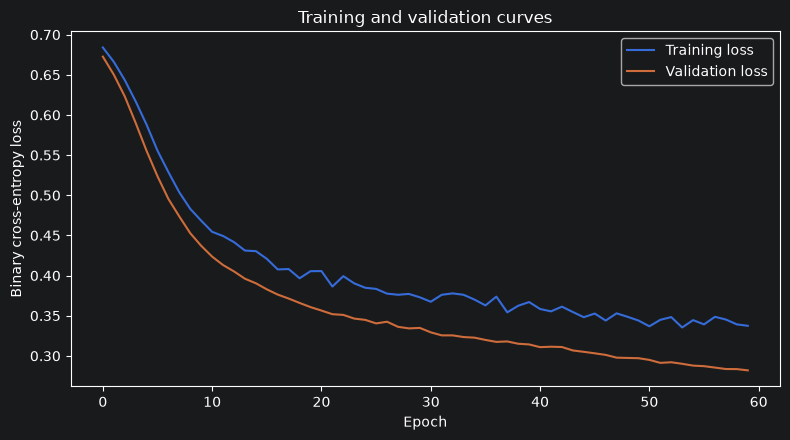

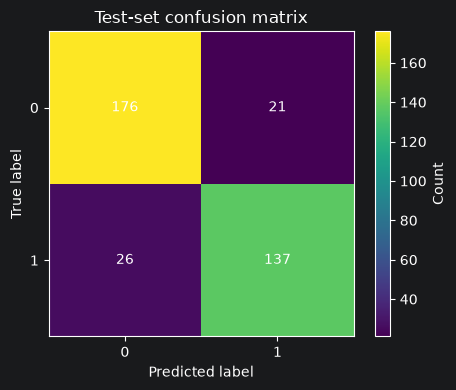

In [3]:
# Plot training and validation loss across epochs.
plt.figure(figsize=(8, 4.5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training and validation curves")
plt.legend()
plt.tight_layout()
plt.show()

# Display the confusion matrix on held-out test data.
cm = confusion_matrix(y_test.astype(int), test_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Test-set confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks([0, 1], labels=["0", "1"])
ax.set_yticks([0, 1], labels=["0", "1"])
for (row, col), value in np.ndenumerate(cm):
    ax.text(col, row, str(value), ha="center", va="center")
fig.colorbar(im, ax=ax, label="Count")
plt.tight_layout()
plt.show()

## 6. Permutation Feature Importance

**Permutation importance** measures how much a chosen metric changes when one feature is randomly shuffled while the other columns stay unchanged.

1. Measure baseline performance.
2. Shuffle one feature column.
3. Recalculate the metric.
4. Repeat and summarize the metric decrease.

We use ROC-AUC for this demonstration. In real model development, prefer a validation set for repeated decisions and reserve the test set for final reporting. Importance depends on the metric and dataset.

,feature,importance_mean,importance_std
4,correlated_A,0.1999,0.0247
1,signal_B,0.0967,0.0138
6,noise_A,0.0450,0.0086
2,signal_C,0.0418,0.0082
0,signal_A,0.0335,0.0060
5,correlated_B,0.0253,0.0052
7,noise_B,0.0024,0.0020
3,signal_D,-0.0024,0.0022


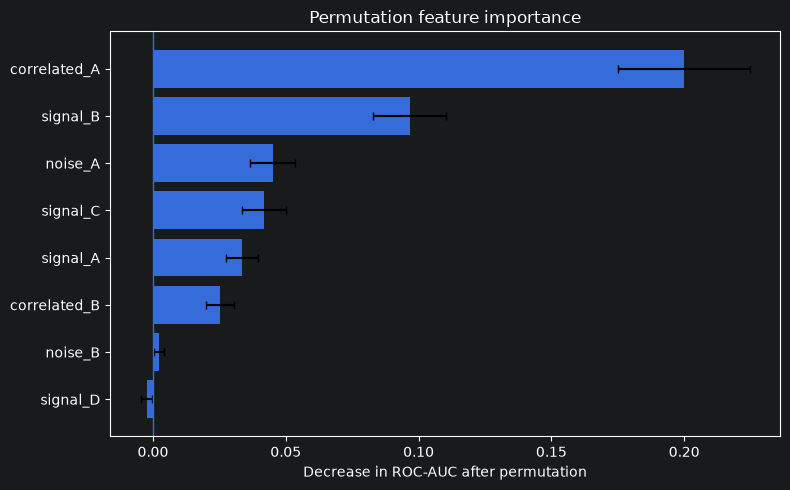

In [4]:
def permutation_importance_auc(model, X_array, y_true, feature_names, n_repeats=10, seed=42):
    # Use a dedicated random generator to make permutations reproducible.
    rng = np.random.default_rng(seed)
    baseline_auc = roc_auc_score(y_true, predict_proba(model, X_array))
    records = []

    for feature_idx, feature_name in enumerate(feature_names):
        shuffled_aucs = []
        for _ in range(n_repeats):
            # Copy the matrix so every repeat starts from the same data.
            X_permuted = X_array.copy()
            # Shuffle only the selected feature across samples.
            X_permuted[:, feature_idx] = rng.permutation(X_permuted[:, feature_idx])
            shuffled_aucs.append(roc_auc_score(y_true, predict_proba(model, X_permuted)))

        # Positive importance means shuffling reduced ROC-AUC on average.
        drops = baseline_auc - np.asarray(shuffled_aucs)
        records.append({
            "feature": feature_name,
            "importance_mean": float(drops.mean()),
            "importance_std": float(drops.std(ddof=1)) if len(drops) > 1 else 0.0
        })
    return pd.DataFrame(records).sort_values("importance_mean", ascending=False)

importance_df = permutation_importance_auc(
    model, X_test, y_test, feature_names, n_repeats=10, seed=SEED
)
display(importance_df.round(4))

# Plot mean importance and standard deviation across repeats.
plot_df = importance_df.sort_values("importance_mean")
plt.figure(figsize=(8, 5))
plt.barh(plot_df["feature"], plot_df["importance_mean"],
         xerr=plot_df["importance_std"], capsize=3)
plt.axvline(0, linewidth=1)
plt.xlabel("Decrease in ROC-AUC after permutation")
plt.title("Permutation feature importance")
plt.tight_layout()
plt.show()

### Interpreting permutation importance

- **Larger positive values:** shuffling the feature tended to hurt ROC-AUC.
- **Values near zero:** shuffling had little measurable effect in this experiment.
- **Negative values:** shuffling sometimes improved the score, possibly due to sampling variability or an unhelpful feature.

Correlated features can substitute for one another. Importance is not a causal effect or an intrinsic property of a feature.

## 7. Partial-Dependence-Style Plot: Vary One Feature

A partial dependence plot (PDP) describes how the average prediction changes as one feature is set to selected values while averaging over other examples. This implementation varies one column and averages predicted probabilities.

PDPs can be misleading when features are correlated because modified rows may contain unrealistic combinations. The plot describes model behavior; it is not a causal analysis.

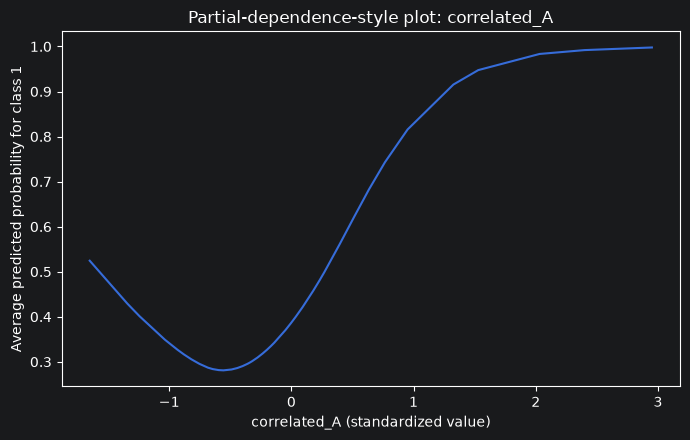

In [5]:
def plot_partial_dependence(model, X_array, feature_names, feature_name, grid_size=40):
    # Find the selected feature's column.
    feature_idx = feature_names.index(feature_name)
    # Use observed quantiles to reduce the influence of extreme values.
    grid = np.quantile(X_array[:, feature_idx], np.linspace(0.02, 0.98, grid_size))
    average_probabilities = []

    for value in grid:
        # Set the chosen feature to this value for every row.
        X_modified = X_array.copy()
        X_modified[:, feature_idx] = value
        # Average class-1 probability across modified rows.
        average_probabilities.append(predict_proba(model, X_modified).mean())

    plt.figure(figsize=(7, 4.5))
    plt.plot(grid, average_probabilities)
    plt.xlabel(f"{feature_name} (standardized value)")
    plt.ylabel("Average predicted probability for class 1")
    plt.title(f"Partial-dependence-style plot: {feature_name}")
    plt.tight_layout()
    plt.show()

# Plot the feature with the highest estimated permutation importance.
top_feature = importance_df.iloc[0]["feature"]
plot_partial_dependence(model, X_test, feature_names, top_feature)

## 8. Local Explanation: Investigate One Prediction

A local explanation investigates one selected sample. We show its standardized inputs, true label, predicted class, and predicted probability.

This is a **descriptive local inspection**, not a formal additive attribution method. Global permutation importance should not be treated as the exact contribution of each feature to this sample's score.

We select a test example with probability closest to 0.5. That is relatively uncertain under the default threshold, but it is not a complete measure of model uncertainty.

Test row index: 97
Predicted probability for class 1: 0.501
Predicted class at threshold 0.5: 1
True class: 1


,feature,standardized_value,importance_mean
4,correlated_A,-0.301,0.200
1,signal_B,0.527,0.097
6,noise_A,-0.344,0.045
2,signal_C,0.073,0.042
0,signal_A,-0.451,0.033
5,correlated_B,-0.644,0.025
7,noise_B,0.132,0.002
3,signal_D,2.195,-0.002


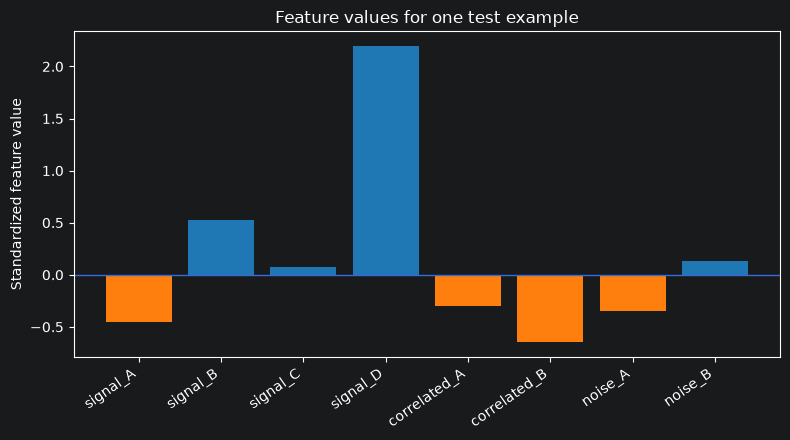

In [6]:
# Select the test example whose predicted probability is closest to 0.5.
sample_idx = int(np.argmin(np.abs(test_prob - 0.5)))
sample_x = X_test[sample_idx:sample_idx + 1]
sample_prob = float(test_prob[sample_idx])
sample_prediction = int(sample_prob >= 0.5)
sample_true = int(y_test[sample_idx])

print("Test row index:", sample_idx)
print(f"Predicted probability for class 1: {sample_prob:.3f}")
print("Predicted class at threshold 0.5:", sample_prediction)
print("True class:", sample_true)

# Combine the sample's values with global importance for context.
local_table = pd.DataFrame({
    "feature": feature_names,
    "standardized_value": sample_x.ravel()
}).merge(importance_df[["feature", "importance_mean"]], on="feature", how="left")
display(local_table.sort_values("importance_mean", ascending=False).round(3))

# Visualize the sample's standardized feature values.
plt.figure(figsize=(8, 4.5))
bar_colors = ["tab:blue" if value >= 0 else "tab:orange" for value in sample_x.ravel()]
plt.bar(feature_names, sample_x.ravel(), color=bar_colors)
plt.axhline(0, linewidth=1)
plt.ylabel("Standardized feature value")
plt.title("Feature values for one test example")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 9. Optional: SHAP for Feature Attributions

**SHAP** attributes a model output to input features using ideas related to Shapley values from cooperative game theory. Different explainers make different assumptions and approximations.

The optional example uses `shap.Explainer` with a prediction function and a small background sample. It may be slower and requires SHAP. If needed, run `%pip install shap` in a separate cell. SHAP values depend on the explainer and background data; they are not universal or causal contributions.

In [7]:
# OPTIONAL: Uncomment these lines if SHAP is installed.
# %pip install shap
#
# import shap
#
# # Provide a prediction function that accepts and returns NumPy arrays.
# def shap_predict_proba(data):
#     return predict_proba(model, np.asarray(data, dtype=np.float32))
#
# # Background data represents the reference distribution for explanations.
# background = X_train[:100]
# rows_to_explain = X_test[:20]  # Keep this small for a quick demonstration.
#
# # Build an explainer for the model's prediction function.
# explainer = shap.Explainer(shap_predict_proba, background)
# shap_values = explainer(rows_to_explain)
#
# # Compare global patterns and one individual example.
# shap.plots.beeswarm(shap_values)
# shap.plots.waterfall(shap_values[0])

## 10. Common Pitfalls and Responsible Use

1. **Treating importance as causation:** predictive association is not necessarily causal.
2. **Ignoring correlated inputs:** redundant features can share or mask importance.
3. **Explaining a poor model:** explanations do not make inaccurate predictions trustworthy.
4. **Repeatedly using test data:** tuning on test results leaks information into development.
5. **Confusing probability with confidence:** probability near 0.5 is not a full uncertainty estimate.
6. **Assuming explanations are stable:** small changes in data or model can change explanations.
7. **Ignoring data quality and bias:** XAI does not automatically detect or correct bias.
8. **Overclaiming local explanations:** a local approximation may not describe the whole model.
9. **Forgetting the audience:** explanations should fit the needs of users and auditors.
10. **Using XAI instead of validation:** assess generalization, calibration when relevant, subgroup behavior, and deployment context.

For high-stakes applications, explanations should be combined with domain expertise, rigorous validation, privacy safeguards, and governance.

## 11. Exercises

1. **Change the random seed.** Retrain and compare importance rankings.
2. **Change the metric.** Adapt permutation importance to use accuracy. Why might rankings change?
3. **Increase repeats.** Try 30 or 50 repeats. How do mean and standard deviation change?
4. **Compare features.** Plot partial dependence for two features. Are the trends monotonic?
5. **Inspect confident examples.** Find a sample with probability below 0.05 or above 0.95 and compare it with the near-0.5 sample.
6. **Correlated features.** Increase redundant features in `make_classification`. What happens to permutation importance?
7. **Optional SHAP.** Compare its summary with permutation importance. Why might rankings differ?

### Reflection questions
- What does permutation importance measure?
- Why is a PDP not a causal effect?
- How do global and local explanations differ?
- What evidence would you want before relying on an explanation in a high-stakes setting?

## 12. Key Takeaways and Quick Reference

### Key takeaways
- Interpretability and explainability help investigate model behavior, but neither guarantees correctness.
- Global explanations summarize overall behavior; local explanations investigate individual predictions.
- Permutation importance estimates metric change after shuffling a feature.
- Partial dependence shows average predictions while varying one feature; correlated inputs can make results unrealistic.
- SHAP provides attributions under method-specific assumptions; attribution is not causation.
- Combine explanations with evaluation, data-quality checks, and robustness analysis.

### Quick reference

| Method | What it provides | Main caution |
|---|---|---|
| Learning curves | Training/validation behavior | Do not prove generalization by themselves |
| Confusion matrix | Threshold-based outcome counts | Depends on threshold and class balance |
| ROC-AUC | Ranking performance across thresholds | Does not assess probability calibration |
| Permutation importance | Metric drop after feature shuffling | Correlation and metric choice matter |
| Partial dependence | Average prediction as a feature varies | May create unrealistic combinations |
| Local inspection | Inputs and output for one sample | Not an additive attribution |
| SHAP | Feature attributions for a chosen explainer | Depends on background data and assumptions |

### Official documentation
- [PyTorch documentation](https://pytorch.org/docs/stable/index.html)
- [PyTorch `nn.Module`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html)
- [scikit-learn permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
- [scikit-learn partial dependence](https://scikit-learn.org/stable/modules/partial_dependence.html)
- [SHAP documentation](https://shap.readthedocs.io/en/latest/)
- [SHAP GitHub repository](https://github.com/shap/shap)

**End of Notebook 10 — Model Interpretability and Explainable AI (XAI).**